# Mpox clade I (Ia and Ib): a sporadic-versus-sustained test

---

### Why this data

Notebook `Mpox/02` found the APOBEC3 mutation signature in clade IIb, and the literature (O'Toole et al. 2023) uses it as a marker of **sustained human transmission**. The first export held no usable clade I genomes (only short fragments), so a second download was made: clade Ia and clade Ib, complete CDS, coverage filters off. This notebook asks the question the clade IIb data could not: **is the APOBEC3 signature weaker in genomes that look like animal-to-human spillover (Ia) than in human-adapted outbreaks (Ib, IIb)?**

### What was done

| Step | Where |
|---|---|
| Raw files organised into one folder per search | `data/Raw/MpoxI/search_605/` (Ia), `search_193/` (Ib) |
| Merged into one table and FASTA | `scripts/merge_gisaid.py MpoxI` |
| Genome composition (GC, CpG, UpA, TpC O/E) | `scripts/build_mpox_features.py MpoxI` |
| Clade, outbreak and lineage calls, substitutions | Nextclade, dataset `nextstrain/mpox/all-clades` |
| APOBEC3 share, cluster size, clock, composition | `scripts/run_mpoxi_analysis.py` |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.abspath("../.."))
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})


## 1. The data

In [2]:
d = pd.read_csv("data/processed/MpoxI/MpoxI_analysis.tsv", sep="\t", low_memory=False)
print(len(d), "clade I genomes (one stray clade IIb genome in the Ib download removed)")
t = d.groupby("group").agg(genomes=("year", "size"), first_year=("year", "min"), last_year=("year", "max"),
                           median_ambiguous=("ambig_frac", "median"),
                           usable=("ambig_frac", lambda s: int((s <= 0.01).sum())))
t["median_ambiguous"] = t.median_ambiguous.round(3)
t

797 clade I genomes (one stray clade IIb genome in the Ib download removed)


,genomes,first_year,last_year,median_ambiguous,usable
group,,,,,
Ia no outbreak,532,1970.0,2026.0,0.031,204
Ia sh2024,73,2024.0,2025.0,0.003,45
Ib sh2023,192,2023.0,2026.0,0.014,85


In [3]:
print(d.Host.value_counts().to_string()); print()
print(d.country.value_counts().head(8).to_string()); print()
print(pd.crosstab(d.group, pd.cut(d.year, [0, 2000, 2015, 2021, 2022, 2023, 2024, 2025, 2027],
      labels=["<=2000", "2001-15", "2016-21", "2022", "2023", "2024", "2025", "2026"])))

Host
Human                            787
unknown                            8
Other: Funisciurus anerythrus      1
Other: Pan troglodytes             1

country
Democratic Republic of the Congo    619
Pakistan                             41
Republic of the Congo                36
Zambia                               25
Brazil                               16
USA                                  13
India                                11
Ireland                              10

year            <=2000  2001-15  2016-21  2022  2023  2024  2025  2026
group                                                                 
Ia no outbreak       9       28       16   109   245   114     5     3
Ia sh2024            0        0        0     0     0    62    11     0
Ib sh2023            0        0        0     0     6    60    60    66


**Reading it.**

- **798 complete genomes downloaded (605 Ia, 193 Ib); 797 kept** after removing one clade IIb genome that came with the Ib download. Most are from the DRC (488 of the 532 Ia genomes outside an outbreak).
- **Quality is the main limit.** Clade I genomes carry many unreadable bases (median 0.3-3% depending on group), and only **334 of 797** have 1% or fewer. All spectrum results below use those.
- **Hosts.** 787 human, 8 unknown, and 2 animals: a **chimpanzee** (Cameroon 2016) and a **rope squirrel** (DRC 2017). Two genomes cannot support a host comparison; both have no recent mutations of their own.
- **Groups come from Nextclade.** *Ib sh2023* and *Ia sh2024* are the two **named outbreaks** with sustained human-to-human spread; *Ia no outbreak* is the rest of clade Ia: older spillover-type genomes (from 1970) and recent DRC cases not assigned to an outbreak.

## 2. The APOBEC3 share of recent mutations

For each genome, "recent" mutations are those it carries relative to its **nearest neighbour in the Nextclade tree**, so lineage-defining changes are excluded. The share is the fraction of those that are **APOBEC3-type** (C to T after a T, or G to A before an A). Filters: at most 1% ambiguous bases and at most 30 recent mutations (more suggests sequencing error). Clade IIb is run with the same filters for comparison. Intervals are bootstrap over genomes, which is **optimistic** because genomes are related.

In [4]:
sh = pd.read_csv("results/mpoxi_apobec_share.tsv", sep="\t")
order = ["Ia no outbreak", "Ia sh2024", "Ib sh2023", "IIb lineage A (pre-2022)", "IIb B-J (2022 outbreak)"]
sh = sh.set_index("group").reindex(order)
sh.round(3)

,genomes,recent mutations,APOBEC3 share,ci_lo,ci_hi,median per-genome share (>=3 mutations)
group,,,,,,
Ia no outbreak,197,707,0.109,0.090,0.129,0.106
Ia sh2024,45,309,0.172,0.136,0.211,0.167
Ib sh2023,84,642,0.478,0.419,0.539,0.500
IIb lineage A (pre-2022),206,580,0.669,0.554,0.789,1.000
IIb B-J (2022 outbreak),7307,18502,0.725,0.713,0.737,0.800


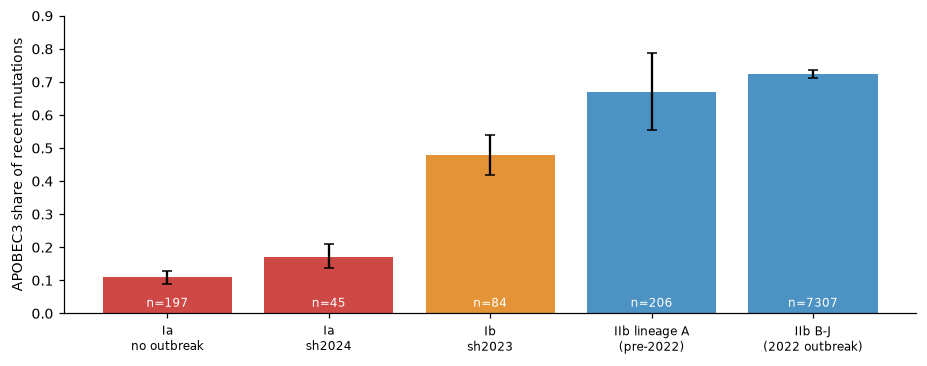

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
cols = ["#C62824", "#C62824", "#E08214", "#2C7FB8", "#2C7FB8"]
ax.bar(range(len(sh)), sh["APOBEC3 share"], color=cols, alpha=.85)
ax.errorbar(range(len(sh)), sh["APOBEC3 share"], yerr=[sh["APOBEC3 share"] - sh.ci_lo, sh.ci_hi - sh["APOBEC3 share"]], fmt="none", color="black", capsize=3)
for i, (g, n) in enumerate(zip(sh.index, sh.genomes)):
    ax.text(i, 0.02, f"n={n}", ha="center", fontsize=8, color="white")
ax.set_xticks(range(len(sh))); ax.set_xticklabels([x.replace(" (", "\n(").replace(" sh", "\nsh").replace(" no", "\nno") for x in sh.index], fontsize=8)
ax.set_ylabel("APOBEC3 share of recent mutations"); ax.set_ylim(0, 0.9)
plt.tight_layout(); fig.savefig("results/figures/mpoxi_apobec_share.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.** There is a clear ordering:

| Group | APOBEC3 share | What it is |
|---|---|---|
| Ia, no outbreak | **0.11** (0.09 to 0.13) | spillover-type clade I genomes |
| Ia outbreak (sh2024) | **0.17** (0.14 to 0.21) | a named human-to-human outbreak |
| Ib outbreak (sh2023) | **0.48** (0.42 to 0.54) | the 2023 human-adapted outbreak |
| IIb pre-2022 lineage A | 0.67 (0.55 to 0.79) | West African clade IIb |
| IIb 2022 outbreak (B to J) | **0.73** (0.71 to 0.74) | the 2022 global outbreak |

The **sporadic-looking clade I genomes have the lowest APOBEC3 share, as the literature predicts**, and the sustained human outbreaks have higher shares. But two results do not fit a simple story:

- **The Ia outbreak (sh2024) is only 0.17**, close to Ia without an outbreak. A named sustained-spread outbreak with a weak APOBEC3 signal needs explaining. It may simply be a very recent outbreak with few APOBEC3 changes accumulated yet, or the estimate may be affected by sequencing errors in these DRC genomes. It is not what the literature reported (a Kinshasa preprint puts about 63% of Ia and 66% of Ib mutations at APOBEC3-type; those were counted differently, so the numbers are not directly comparable, and I did not verify that preprint's publication status).
- **Ib at 0.48 is well below IIb at 0.73**, even though both are human-adapted. A plausible reading is that clade I has been circulating in humans for a shorter time, so its recent mutations are still a mix of APOBEC3 changes and others. That is a hypothesis, not a result.

## 3. An independent check: does the signature rise with cluster size?

The outbreak labels come from a nomenclature built around **sustained human transmission**, so they are not independent of the APOBEC3 signal: comparing groups by APOBEC3 share is partly circular. A check that does not use the spectrum: for each genome, how many **other genomes lie within 5 substitutions** of it. Sustained spread makes large near-identical clusters; a one-off spillover tends to be a singleton.

In [6]:
x = d[d.good & d.cluster_class.notna()]
t = x.groupby(["group", "cluster_class"], observed=True).agg(genomes=("priv", "size"), mutations=("priv", "sum"),
                                                     apobec=("priv_apobec", "sum"))
t["APOBEC3 share"] = (t.apobec / t.mutations).round(3)
t[["genomes", "mutations", "APOBEC3 share"]]

genomes  mutations  APOBEC3 share
group          cluster_class                                                 
Ia no outbreak large (5+)                        21        128          0.109
               singleton (0 within 5 SNPs)      112        404          0.106
               small (1-4)                       64        175          0.114
Ia sh2024      singleton (0 within 5 SNPs)       37        279          0.158
               small (1-4)                        8         30          0.300
Ib sh2023      large (5+)                        21        138          0.688
               singleton (0 within 5 SNPs)       48        414          0.389
               small (1-4)                       15         90          0.567

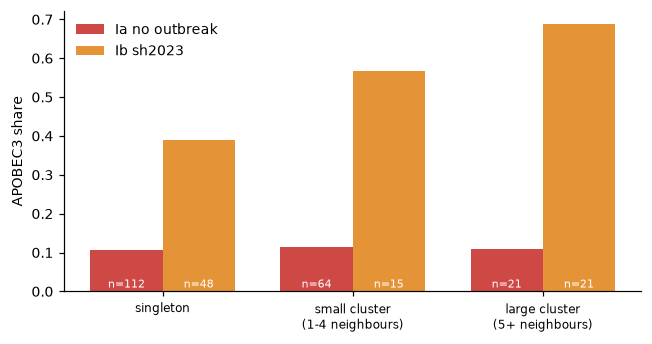

In [7]:
ib = t.loc["Ib sh2023"].reindex(["singleton (0 within 5 SNPs)", "small (1-4)", "large (5+)"])
ia = t.loc["Ia no outbreak"].reindex(["singleton (0 within 5 SNPs)", "small (1-4)", "large (5+)"])
fig, ax = plt.subplots(figsize=(6, 3.2))
w = .38; xs = np.arange(3)
ax.bar(xs - w/2, ia["APOBEC3 share"], w, color="#C62824", alpha=.85, label="Ia no outbreak")
ax.bar(xs + w/2, ib["APOBEC3 share"], w, color="#E08214", alpha=.85, label="Ib sh2023")
for i in range(3):
    ax.text(i - w/2, 0.01, f"n={int(ia.genomes.iloc[i])}", ha="center", fontsize=7, color="white")
    ax.text(i + w/2, 0.01, f"n={int(ib.genomes.iloc[i])}", ha="center", fontsize=7, color="white")
ax.set_xticks(xs); ax.set_xticklabels(["singleton", "small cluster\n(1-4 neighbours)", "large cluster\n(5+ neighbours)"], fontsize=8)
ax.set_ylabel("APOBEC3 share"); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig("results/figures/mpoxi_cluster_class.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.**

- **Inside Ib, the share rises with cluster size**: 0.39 for singletons, 0.57 for small clusters and **0.69 for large ones**. That is the pattern expected if genomes in large chains are the human-adapted ones, and it does not depend on the outbreak label.
- **Inside Ia without an outbreak the share does not move** (0.11, 0.11, 0.11), even for the 21 genomes in large clusters. So a large near-identical cluster does not by itself mean APOBEC3-driven human spread; the Ia clusters may be local chains of zoonotic origin. This is the clearest point where the two clades differ.
- **Limit:** the Ib cell counts are small (21 genomes in large clusters), and a genome in a large cluster has few recent mutations by construction, so the shares there are noisy.

## 4. The mutation clock inside the outbreaks

Same test as for clade IIb (notebook `Mpox/02`): APOBEC3-type changes since the outbreak's founder, against collection date, with errors clustered by lineage (Ib) or country (Ia).

In [8]:
ck = pd.read_csv("results/mpoxi_clock.tsv", sep="\t")
ck[ck.feature.isin(["fm_apobec", "gc_content", "oe_TC"])][["lineage_grp", "feature", "n", "slope", "ci_lo", "ci_hi", "p", "n_clusters"]].round(6)

,lineage_grp,feature,n,slope,ci_lo,ci_hi,p,n_clusters
0,Ib sh2023,fm_apobec,76,2.595398,-3.292526,8.483323,0.322207,7
2,Ib sh2023,gc_content,76,-0.000120,-0.000297,0.000056,0.145690,7
3,Ib sh2023,oe_TC,76,-0.000162,-0.000714,0.000391,0.501488,7
4,Ia sh2024,fm_apobec,45,4.771022,-1.717221,11.259264,0.101207,4
6,Ia sh2024,gc_content,45,-0.000096,-0.000800,0.000609,0.694983,4
7,Ia sh2024,oe_TC,45,-0.000166,-0.003200,0.002868,0.872826,4


**Reading it.** The slopes are **positive but not distinguishable from zero** (Ib: 2.6 per year, 95% interval -3.3 to 8.5, 76 genomes; Ia sh2024: 4.8 per year, interval -1.7 to 11.3, 45 genomes). The outbreaks span only 2-3 years and few genomes pass the 1% ambiguity filter, so there is **not enough data to confirm a clock** here (clade IIb's was 5.3 per year with 5,000 genomes). GC and TpC do not move either.

## 5. Composition by group

In [9]:
c = pd.read_csv("results/mpoxi_group_summary.tsv", sep="\t", index_col=0).reindex(order)
c.round(4)

,genomes,gc,cpg_oe,upa_oe,tpc_oe
group,,,,,
Ia no outbreak,532,0.3309,1.0382,0.9928,1.1339
Ia sh2024,73,0.3318,1.0386,0.9888,1.1383
Ib sh2023,192,0.3310,1.0386,0.9904,1.1370
IIb lineage A (pre-2022),206,0.3302,1.0370,0.9936,1.1350
IIb B-J (2022 outbreak),7307,0.3300,1.0355,0.9936,1.1338


**Reading it.** Composition is nearly the same everywhere: GC 0.330 to 0.332, CpG O/E about 1.04, UpA about 0.99, TpC about 1.13 to 1.14. Clade I is a little higher in GC than IIb (0.331 against 0.330), a tiny difference between clades, not between sporadic and sustained groups. As in clade IIb, **composition is a poor read-out for mpox**; the mutation spectrum is the informative measure.

## 6. What this means

| Question | Answer |
|---|---|
| Do we now have a sporadic-versus-sustained contrast? | **Partly.** The APOBEC3 share is lowest in the spillover-type Ia genomes (0.11) and highest in IIb (0.73), with Ib in between (0.48). |
| Does an independent marker agree? | **Inside Ib, yes** (cluster size rises with the share, 0.39 to 0.69). **Inside Ia, no** (flat at 0.11). |
| Is the Ia outbreak (sh2024) APOBEC3-driven? | **Not clearly** (0.17), which differs from the literature's reported level. Needs checking. |
| Is the clock confirmed in clade I? | **No.** Too few genomes and too short a span. |
| Does composition separate the groups? | **No.** The differences are in the third decimal. |

### Limits

- **Quality:** only 334 of 797 genomes pass the 1% ambiguity filter; the clade Ia and Ib genomes from the DRC carry many gaps, and sequencing errors would add non-APOBEC mutations and lower the share.
- **Definition of "recent":** relative to the nearest Nextclade tree node, whose density differs between clades. A sparse region of the tree makes a genome's "recent" mutations include older ones.
- **Circularity:** the outbreak labels are not independent of the signature (section 3 is the independent check).
- **Related genomes:** bootstrap intervals treat genomes as independent; they are not.

### Next steps

1. **Check the Ia outbreak's low share** with a second method: build our own tree for clade I (IQ-TREE) and reconstruct ancestral states, so "recent mutations" do not depend on the Nextclade tree.
2. **Add the date and location detail** (Kinshasa versus elsewhere) to see whether the low Ia share is a recent-outbreak effect.
3. **Ask the mentor** whether this APOBEC3-marker route (mpox) is where to go, or whether to return to the host-based design with SARS-CoV-2 / H5N1.